# Tutorial 2 - Enrich a pre-created PyPSA model with new elements

## 1. Re-load the model of the NL created in Tutorial 1

In [1]:
import pypsa
import pandas as pd

In [2]:
n = pypsa.Network("output_data/saved_model.xlsx")

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.4)
INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, loads, sub_networks


In [3]:
n

PyPSA Network 'Unnamed Network'
-------------------------------
Components:
 - Bus: 1
 - Carrier: 9
 - Generator: 8
 - Load: 1
 - SubNetwork: 1
Snapshots: 8760

In [4]:
# And let's reload the techno-economic parameters, since the battery will need them
technoecon_params = pd.read_csv('input_data/technoecon_params.csv', index_col=0)

In [5]:
technoecon_params

,fuel,VOM,efficiency,FOM,CO2 intensity,lifetime,investment,installed_capacity
ccgt,11.6278,5.8775,0.5600,3.3295,0.1980,25.0,1175506.7,17470.5
solar,0.0000,0.0134,0.0000,1.5780,0.0000,35.0,1018204.4,7366.1
wind-onshore,0.0000,2.0037,0.0000,1.2514,0.0000,27.0,1494463.1,5505.8
wind-offshore,0.0000,0.0267,0.0000,2.5093,0.0000,27.0,2505378.1,7138.0
nuclear,7.4536,4.4590,0.3260,1.2700,0.0000,40.0,10805703.8,515.0
battery,0.0000,0.0000,0.9500,0.2000,0.0000,15.0,1601785.4,263.4
biomass,9.3506,2.8138,0.2994,3.6081,NaN,25.0,4516713.3,1573.2
coal,7.8202,4.1005,0.3560,1.3100,0.3361,40.0,4812024.4,6007.0


## 2. Introduce a new technology: battery storage

In [6]:
n.add("Carrier", name="battery", color='cyan')

n.add(
    "StorageUnit",
    "battery",
    bus="electricity",
    carrier="battery",
    max_hours=4,
    capital_cost=technoecon_params.loc['battery','investment'],
    efficiency_store=technoecon_params.loc['battery','efficiency'],
    efficiency_dispatch=technoecon_params.loc['battery','efficiency'],
    cyclic_state_of_charge=True, # Ensures that energy is the same at the start and end of the problem, avoiding 'for-free' initial stored energy
    p_nom=technoecon_params.loc['battery','installed_capacity']
)


In [7]:
n.optimize()

/tmp/ipykernel_91573/1261279110.py:1: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|█████████████| 4/4 [00:00<00:00, 257.66it/s]
INFO:linopy.io: Writing time: 0.23s


Running HiGHS 1.12.0 (git hash: 755a8e0): Copyright (c) 2025 HiGHS under MIT licence terms
LP linopy-problem-s5cu79fu has 245276 rows; 96360 cols; 385432 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [1e-02, 2e+02]
  Bound   [0e+00, 0e+00]
  RHS     [6e-01, 2e+04]
Presolving model
52556 rows, 74754 cols, 171106 nonzeros  0s
28922 rows, 53417 cols, 90269 nonzeros  0s
Dependent equations search running on 11404 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
28922 rows, 53417 cols, 90269 nonzeros  0s
Presolve reductions: rows 28922(-216354); columns 53417(-42943); nonzeros 90269(-295163) 
Solving the presolved LP
Using EKK dual simplex solver - serial
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0s
      12637     1.9657607554e+09 Pr: 0(0); Du: 0(5.32907e-15) 1s

Performed postsolve
Solving the original LP from the solution after postsolve



INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 96360 primals, 350400 duals
Objective: 1.97e+09
Solver: highs
Runtime: 0.82s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-p-ramp_limit_up, Generator-p-ramp_limit_down, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


('ok', 'optimal')

### 2.1 Inspect the results with the new technology

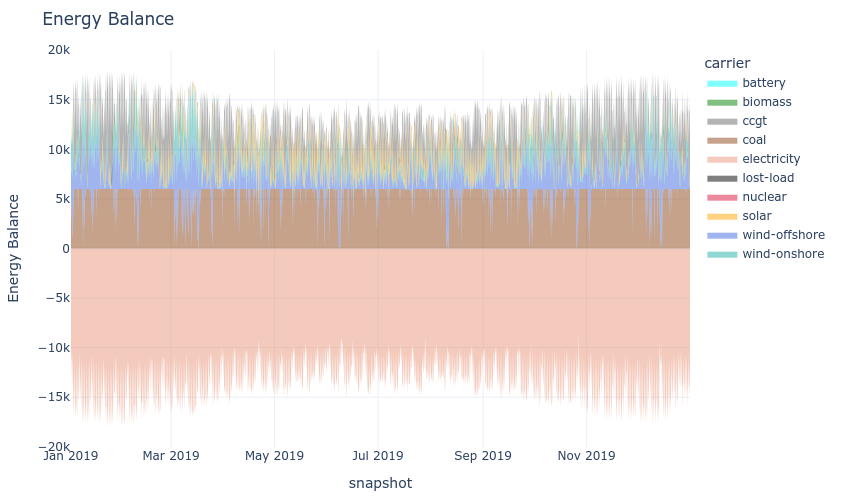

In [8]:
# Energy balance
n.statistics.energy_balance.iplot.area()

### 2.2 Make the results more interesting: more renewables and more battery

In [9]:
n.generators.loc['wind-offshore','p_nom'] = 2*n.generators.loc['wind-offshore','p_nom']
n.generators.loc['solar','p_nom'] = 1.5*n.generators.loc['solar','p_nom']
n.storage_units.loc['battery','p_nom'] = 100*n.storage_units.loc['battery','p_nom']

/tmp/ipykernel_91573/119454345.py:1: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|█████████████| 4/4 [00:00<00:00, 234.55it/s]
INFO:linopy.io: Writing time: 0.18s


Running HiGHS 1.12.0 (git hash: 755a8e0): Copyright (c) 2025 HiGHS under MIT licence terms
LP linopy-problem-gz8lb77a has 245276 rows; 96360 cols; 385432 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [1e-02, 2e+02]
  Bound   [0e+00, 0e+00]
  RHS     [6e-01, 1e+05]
Presolving model
52556 rows, 91998 cols, 188350 nonzeros  0s
Dependent equations search running on 17520 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
35038 rows, 91998 cols, 153314 nonzeros  0s
Presolve reductions: rows 35038(-210238); columns 91998(-4362); nonzeros 153314(-232118) 
Solving the presolved LP
Using EKK dual simplex solver - serial
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Pr: 8760(1.13901e+08) 0s
      26526     1.3490375868e+09 Pr: 0(0); Du: 0(1.9984e-14) 1s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-pr

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 96360 primals, 350400 duals
Objective: 1.35e+09
Solver: highs
Runtime: 1.25s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-p-ramp_limit_up, Generator-p-ramp_limit_down, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


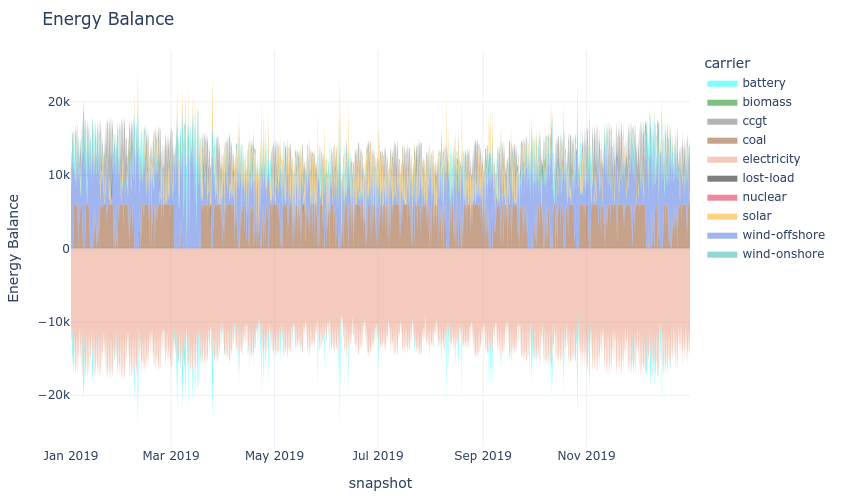

In [10]:
n.optimize()
n.statistics.energy_balance.iplot.area()

<Axes: title={'center': 'Price dynamics'}, xlabel='snapshot'>

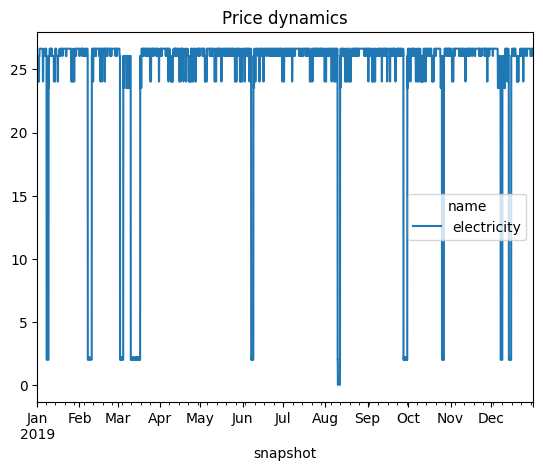

In [11]:
# Prices over time
n.buses_t.marginal_price.loc['2019-01-01':'2019-12-31'].plot(title="Price dynamics")

<Axes: >

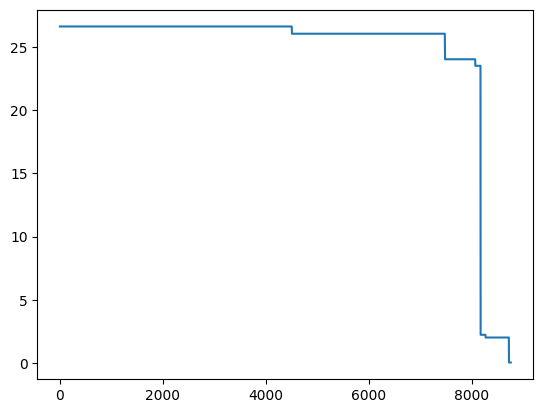

In [12]:
pdc = n.buses_t.marginal_price['electricity'].loc['2019-01-01':'2019-12-31'].sort_values(ascending=False).reset_index(drop=True)
pdc.plot()

In [13]:
# Simplified (i.e., no discount rate) cost recovery example
total_investment = (technoecon_params['investment']*n.generators.p_nom).dropna() # As long as tech names are the same
yearly_revenues = n.statistics.revenue(carrier=total_investment.index).droplevel("component")
payback_time = total_investment/yearly_revenues
payback_time

TypeError: Argument `carrier` must be a string or list, got <class 'pandas.core.indexes.base.Index'>

In [ ]:
n.carriers

## 3. Introduce a carbon tax 
Let's start again from the initial model, without battery or expanded renewables

In [ ]:
n = pypsa.Network("output_data/saved_model.xlsx")

### 3.1 Define the tax and convert to marginal extra-cost per generator

In [ ]:
carbon_tax = 80 # Eur per tonnes of CO2

In [ ]:
co2_in_fuels = n.carriers['co2_emissions'].loc[n.generators.index]
co2_in_fuels

In [ ]:
carbon_tax_per_mwh = carbon_tax*co2_in_fuels/n.generators['efficiency']
carbon_tax_per_mwh

In [ ]:
n.generators.marginal_cost # Before the tax

In [ ]:
n.generators.marginal_cost = n.generators.marginal_cost + carbon_tax_per_mwh
n.generators.marginal_cost # After the tax

### 3.2 Re-run the model and see how the merit order and prices change

In [ ]:
n.optimize()
n.statistics.energy_balance.iplot.area()

In [ ]:
# Prices over time
n.buses_t.marginal_price.loc['2019-01-01':'2019-12-31'].plot(title="Price dynamics")

In [ ]:
n.buses_t.marginal_price['electricity']

In [ ]:
pdc = n.buses_t.marginal_price['electricity'].loc['2019-01-01':'2019-12-31'].sort_values(ascending=False).reset_index(drop=True)
pdc.plot()

In [ ]:
# Simplified (i.e., no discount rate) cost recovery example
total_investment = (technoecon_params['investment']*n.generators.p_nom).dropna() # As long as tech names are the same
yearly_revenues = n.statistics.revenue(carrier=total_investment.index).droplevel("component")
payback_time = total_investment/yearly_revenues
payback_time

In [ ]:
n.statistics.market_value(components='Generator')

In [ ]:
# TODO: add small operating cost to the battery to avoid cycling
# TODO: fix errors
# TODO: introduce battery immediately with higher capacity?